Sample Database Activity Dataset:
   Query_Length  Special_Characters  Failed_Login_Attempts  Query_Frequency  \
0           112                  10                      3               24   
1           445                   6                      5               42   
2           358                  13                      5                9   
3           280                   3                      2               26   
4           116                  12                      8               20   

   Privilege_Level  External_IP  Data_Modification  Unusual_Query  Malicious  
0                2            0                  0              0          0  
1                2            1                  0              1          1  
2                2            0                  0              1          0  
3                4            1                  1              1          1  
4                1            0                  0              1          1  

Training samples

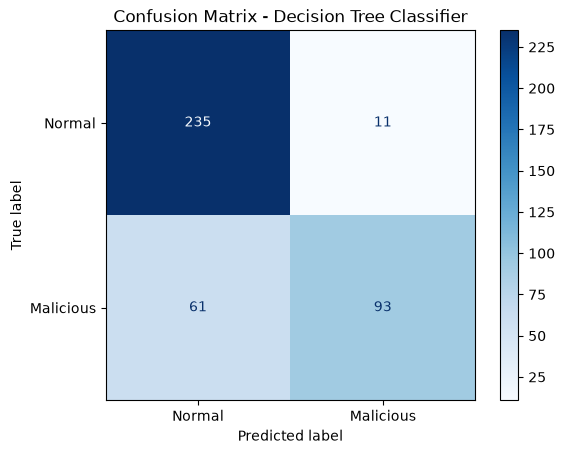

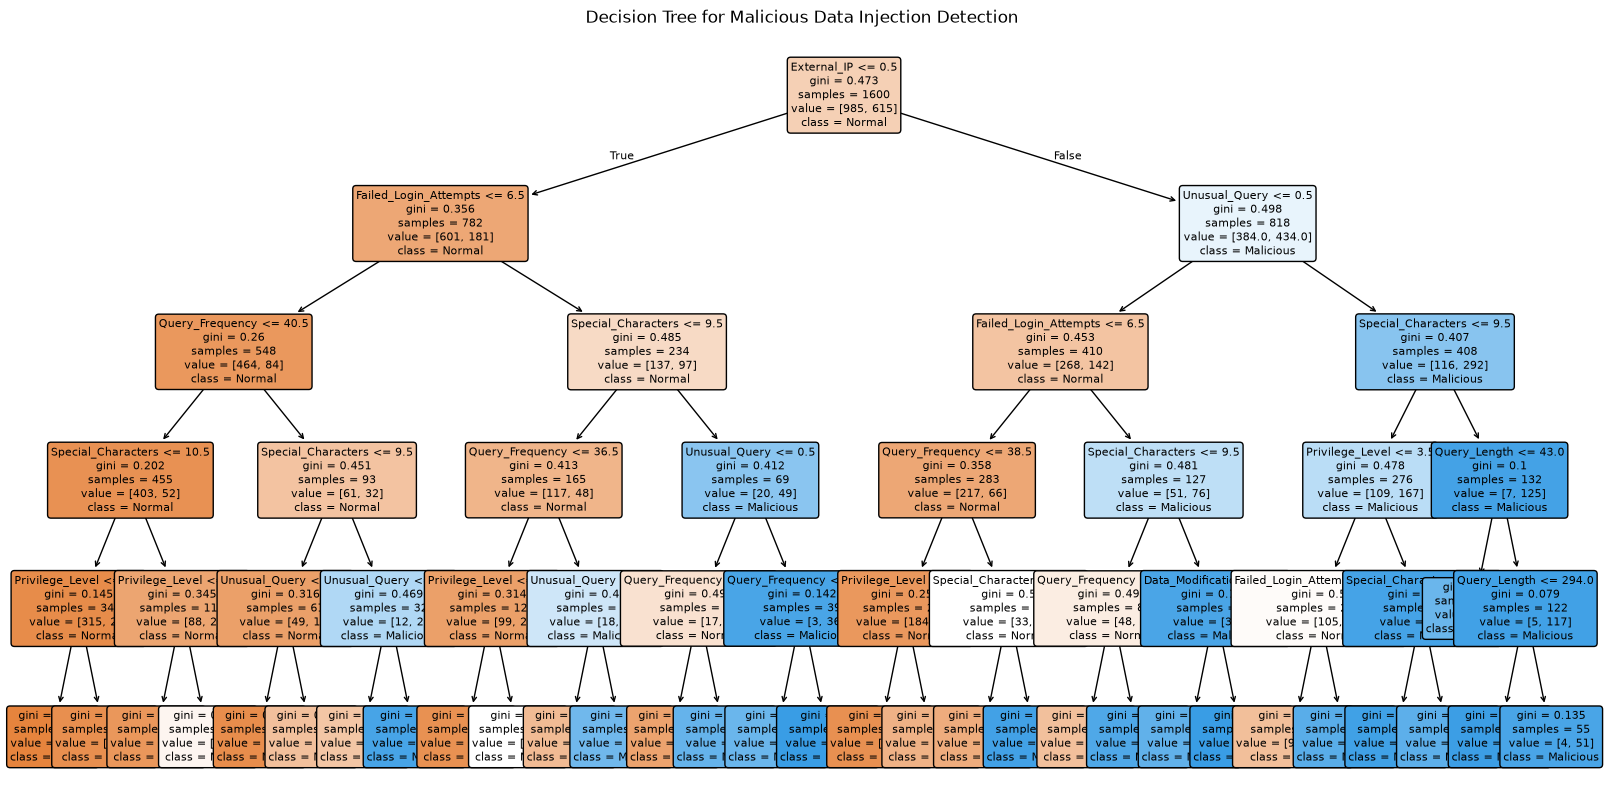


Feature Importance:
                 Feature  Importance
7          Unusual_Query    0.202106
1     Special_Characters    0.201508
5            External_IP    0.191139
2  Failed_Login_Attempts    0.188833
3        Query_Frequency    0.120550
4        Privilege_Level    0.092670
0           Query_Length    0.001788
6      Data_Modification    0.001406


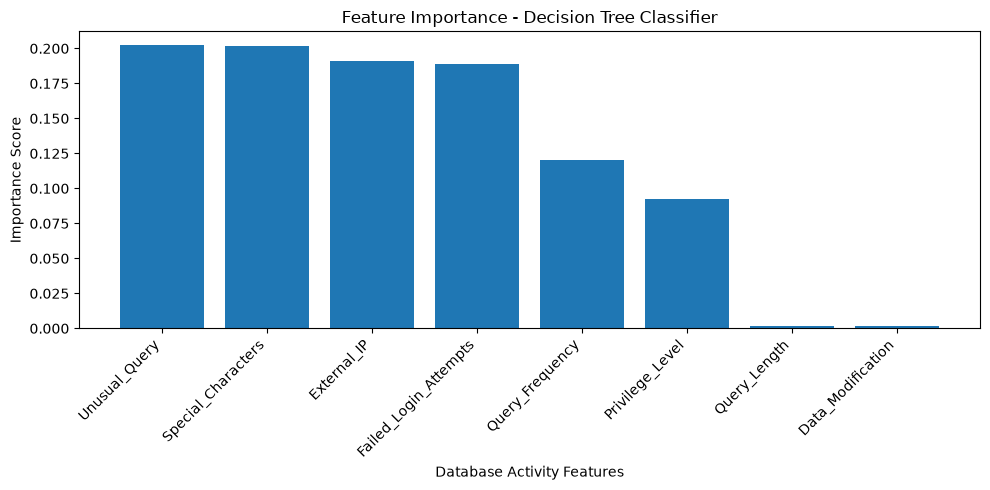


New Database Activity Analysis:
ALERT: Potential Malicious Data Injection Detected!

Prediction Probabilities:
Normal Activity: 7.27%
Malicious Activity: 92.73%

Experiment Completed Successfully!


In [1]:
# Experiment 11: Develop a decision tree classifier to detect malicious data injections within databases.

# Experiment: Malicious Data Injection Detection
# Using Decision Tree Classifier
# Machine Learning for Cybersecurity

# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Step 2: Generate a sample database activity dataset
# The dataset contains normal and malicious database operations.

np.random.seed(42)

n_samples = 2000

data = {
    'Query_Length': np.random.randint(10, 500, n_samples),
    'Special_Characters': np.random.randint(0, 15, n_samples),
    'Failed_Login_Attempts': np.random.randint(0, 10, n_samples),
    'Query_Frequency': np.random.randint(1, 50, n_samples),
    'Privilege_Level': np.random.randint(1, 5, n_samples),
    'External_IP': np.random.randint(0, 2, n_samples),
    'Data_Modification': np.random.randint(0, 2, n_samples),
    'Unusual_Query': np.random.randint(0, 2, n_samples)
}

df = pd.DataFrame(data)

# Step 3: Create target labels
# 0 = Normal database activity
# 1 = Malicious data injection

risk_score = (
    (df['Special_Characters'] > 9).astype(int) +
    (df['Failed_Login_Attempts'] > 6).astype(int) +
    (df['Query_Frequency'] > 38).astype(int) +
    (df['External_IP'] == 1).astype(int) +
    (df['Unusual_Query'] == 1).astype(int) +
    (df['Privilege_Level'] == 4).astype(int)
)

# Introduce some uncertainty into the labels
# to simulate realistic classification challenges.

df['Malicious'] = (risk_score >= 3).astype(int)

noise = np.random.choice([0, 1], size=n_samples, p=[0.90, 0.10])
df['Malicious'] = np.where(
    noise == 1,
    1 - df['Malicious'],
    df['Malicious']
)

# Display first five records
print("Sample Database Activity Dataset:")
print(df.head())

# Step 4: Separate features and target variable

X = df.drop('Malicious', axis=1)
y = df['Malicious']

# Step 5: Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# Step 6: Create and train Decision Tree Classifier

model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

model.fit(X_train, y_train)

print("\nDecision Tree model trained successfully!")

# Step 7: Predict database activity

y_pred = model.predict(X_test)

# Step 8: Calculate model accuracy

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy: {:.2f}%".format(accuracy * 100))

# Step 9: Display classification report

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Normal Activity', 'Malicious Activity']
))

# Step 10: Display confusion matrix

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Normal', 'Malicious']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Decision Tree Classifier')
plt.show()

# Step 11: Visualize the Decision Tree

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['Normal', 'Malicious'],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title('Decision Tree for Malicious Data Injection Detection')
plt.show()

# Step 12: Display feature importance

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nFeature Importance:")
print(importance)

plt.figure(figsize=(10, 5))

plt.bar(
    importance['Feature'],
    importance['Importance']
)

plt.xlabel('Database Activity Features')
plt.ylabel('Importance Score')
plt.title('Feature Importance - Decision Tree Classifier')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Step 13: Test the model with a new database activity

new_activity = pd.DataFrame({
    'Query_Length': [450],
    'Special_Characters': [12],
    'Failed_Login_Attempts': [8],
    'Query_Frequency': [45],
    'Privilege_Level': [4],
    'External_IP': [1],
    'Data_Modification': [1],
    'Unusual_Query': [1]
})

prediction = model.predict(new_activity)

print("\nNew Database Activity Analysis:")

if prediction[0] == 1:
    print("ALERT: Potential Malicious Data Injection Detected!")
else:
    print("SAFE: Normal Database Activity Detected.")

# Display prediction probability

probability = model.predict_proba(new_activity)

print("\nPrediction Probabilities:")
print("Normal Activity: {:.2f}%".format(probability[0][0] * 100))
print("Malicious Activity: {:.2f}%".format(probability[0][1] * 100))

# Step 14: Experiment completed

print("\nExperiment Completed Successfully!")

